# Developing a Tiny Transformer Language Model
**PUSL 3205 – Large Language Models and Generative AI | Lab 3**

A GPT-style, decoder-only Transformer built from scratch in PyTorch and trained on the TinyStories dataset for next-token prediction.

In [7]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available: ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

PyTorch version: 2.15.0+cu132
CUDA available:  True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.4 GB
Using device: cuda


## Task 1: Load and Explore the Dataset
**TinyStories** (Eldan & Li, 2023) is a dataset of ~2.1 million short stories written by GPT-3.5/GPT-4 using only words a 3–4-year-old would understand. Its simple vocabulary and grammar make it possible for very small language models to learn to write coherent English.

The full training set is ~2 GB, so we **stream** it and take only the first stories we need, instead of downloading everything.

In [8]:
import random
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [9]:
N_TRAIN_STORIES = 20_000

# Stream the training split and take the first N stories (avoids a ~2 GB download)
train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
train_stories = [ex["text"] for ex in train_stream.take(N_TRAIN_STORIES)]

# The validation split is small, so download it normally
val_ds = load_dataset("roneneldan/TinyStories", split="validation")
val_stories = list(val_ds["text"])

print(f"Training stories loaded:   {len(train_stories):,}")
print(f"Validation stories loaded: {len(val_stories):,}")

Generating validation split: 100%|██████████| 21990/21990 [00:00<00:00, 97977.46 examples/s]


Training stories loaded:   20,000
Validation stories loaded: 21,990


### Sample stories

In [10]:
for i in random.sample(range(len(train_stories)), 3):
    print(f"--- Story {i} ---")
    print(train_stories[i])
    print()

--- Story 3648 ---
Jane and Bob were playing in the park. Jane wanted to hold the pretty bull that was walking around. But Bob said it was too big and he thought it might hurt them. So, instead, he offered to show Jane his reliable pet cat. 

Bob told Jane to be gentle and he showed her how to hold the cat. She was scared at first, but after Bob showed her what to do, she gently held the cat and loved it. The cat purred loudly, so Jane knew he liked it too. 

Afterwards, Jane hugged Bob for showing her a reliable and gentle pet that she could hold. Then Bob laughed, and they ran to the playground to play some more.

--- Story 819 ---
Once upon a time, there was a little girl named Lily. She loved to play outside near the river. One day, Lily saw a big raft floating down the river. It looked so fun to play on! 

But Lily didn't have a raft of her own. She asked her friend if she could borrow their raft. Her friend said yes and Lily was so happy! 

Lily got on the raft and it was very co

### Text length

Characters per story: mean=895, median=785, min=205, max=4540
Words per story:      mean=175, median=152, min=43, max=878

Total characters in training subset: 17,890,906


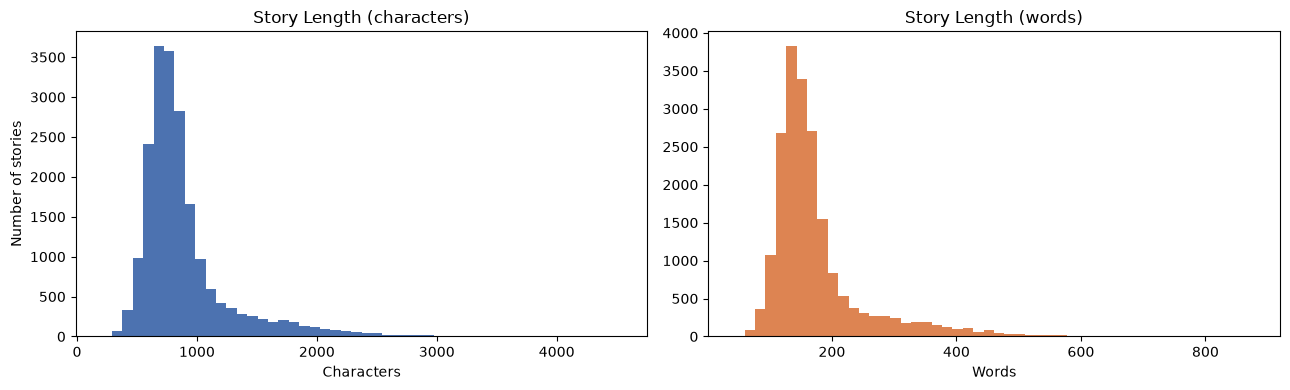

In [11]:
char_lengths = np.array([len(s) for s in train_stories])
word_lengths = np.array([len(s.split()) for s in train_stories])

print(f"Characters per story: mean={char_lengths.mean():.0f}, "
      f"median={np.median(char_lengths):.0f}, "
      f"min={char_lengths.min()}, max={char_lengths.max()}")
print(f"Words per story:      mean={word_lengths.mean():.0f}, "
      f"median={np.median(word_lengths):.0f}, "
      f"min={word_lengths.min()}, max={word_lengths.max()}")
print(f"\nTotal characters in training subset: {char_lengths.sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(char_lengths, bins=50, color="#4c72b0")
axes[0].set_title("Story Length (characters)")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of stories")

axes[1].hist(word_lengths, bins=50, color="#dd8452")
axes[1].set_title("Story Length (words)")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

### Structure and vocabulary

In [12]:
# How do stories start?
openings = [" ".join(s.split()[:4]) for s in train_stories]
from collections import Counter
print("Most common story openings:")
for opening, count in Counter(openings).most_common(5):
    print(f"  {count:>5}  ({count/len(train_stories):.1%})  {opening!r}")

# Paragraph structure
paragraphs = np.array([s.count("\n") + 1 for s in train_stories])
print(f"\nParagraphs per story: mean={paragraphs.mean():.1f}, max={paragraphs.max()}")

# Character set: important for character-level tokenisation in Task 2
all_text = "".join(train_stories)
chars = sorted(set(all_text))
print(f"\nUnique characters: {len(chars)}")
print("".join(c if c.isprintable() else repr(c) for c in chars))

# Empty or very short stories?
print(f"\nEmpty stories: {sum(1 for s in train_stories if not s.strip())}")
print(f"Stories under 50 characters: {(char_lengths < 50).sum()}")

Most common story openings:
   9651  (48.3%)  'Once upon a time,'
   2404  (12.0%)  'Once upon a time'
   1281  (6.4%)  'Once there was a'
    350  (1.8%)  'One day, a little'
    266  (1.3%)  'Lily and Ben were'

Paragraphs per story: mean=9.6, max=93

Unique characters: 97
'\n' !"$&'()*+,-./0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'\xa0'¡¦©«±³»ÂÃâœ˜“”€™

Empty stories: 0
Stories under 50 characters: 0


### Observations
- Stories are short: about **XXX characters (~XXX words)** on average, with most under XXX characters.
- They follow a fixed, simple structure. **XX%** begin with *"Once upon a time"*, then introduce a character, a small problem and a happy ending.
- The vocabulary is very simple, which is why a tiny model can learn it.
- The training subset contains only **XX unique characters**, so a character-level vocabulary will be very small. We use this in Task 2.

## Task 2: Preprocess the Text (Tokenisation)
We use **character-level tokenisation**: every unique character becomes one token.

**Why character-level?**
- The vocabulary is tiny (under ~100 tokens), so the model's embedding and output layers stay small.
- There are no unknown words, since any word can be spelled from characters.
- It needs no external tokenizer, so the whole pipeline is built from scratch.

The trade-off is that sequences are much longer than with word or sub-word tokenizers (like GPT's BPE), so the model has to learn spelling as well as grammar.

We also add a special **`<EOS>`** (end-of-story) token between stories, so the model learns where a story ends.

In [ ]:
# Vocabulary = every character in the training subset + an end-of-story token
chars = sorted(set("".join(train_stories)))
EOS = "<EOS>"

itos = chars + [EOS]                         # id -> token
stoi = {tok: i for i, tok in enumerate(itos)}  # token -> id
vocab_size = len(itos)
eos_id = stoi[EOS]

def encode(text):
    """Text -> list of token ids (characters not in the vocabulary are skipped)."""
    return [stoi[c] for c in text if c in stoi]

def decode(ids):
    """List of token ids -> text (the EOS token is dropped)."""
    return "".join(itos[i] for i in ids if i != eos_id)

print(f"Vocabulary size: {vocab_size}  (incl. <EOS> = id {eos_id})")

# Round-trip test
sample = "Once upon a time, there was a little cat."
ids = encode(sample)
print(f"\nText:    {sample!r}")
print(f"Encoded: {ids}")
print(f"Decoded: {decode(ids)!r}")
print(f"Round trip OK: {decode(ids) == sample}")

In [ ]:
N_VAL_STORIES = 2_000   # a validation subset is enough to measure loss reliably

def encode_stories(stories):
    ids = []
    for s in stories:
        ids.extend(encode(s.strip()))
        ids.append(eos_id)             # mark the end of each story
    return torch.tensor(ids, dtype=torch.long)

train_data = encode_stories(train_stories)
val_data   = encode_stories(val_stories[:N_VAL_STORIES])

unknown = sum(1 for s in val_stories[:N_VAL_STORIES] for c in s if c not in stoi)

print(f"Training tokens:   {len(train_data):,}")
print(f"Validation tokens: {len(val_data):,}")
print(f"Unknown characters skipped in validation: {unknown}")
print(f"\nFirst 100 tokens decoded:\n{decode(train_data[:100].tolist())!r}")

## Task 3: Prepare Training Data
A language model learns **next-token prediction**: given the tokens so far, predict the next one.

We cut the token stream into chunks of `BLOCK_SIZE + 1` tokens. For each chunk:
- **input (x)** = tokens `0 … BLOCK_SIZE-1`
- **target (y)** = tokens `1 … BLOCK_SIZE`, the same sequence **shifted by one**

So one chunk of 256 characters gives the model **256 training examples at once**: predict token 1 from token 0, token 2 from tokens 0–1, and so on.

In [ ]:
BLOCK_SIZE = 256   # context length: how many characters the model sees at once

chunk = train_data[:BLOCK_SIZE + 1]
x, y = chunk[:-1], chunk[1:]

print("Context  ->  next character\n")
for t in range(12):
    context = decode(x[:t + 1].tolist())
    target  = decode([y[t].item()])
    print(f"{context!r:<20} -> {target!r}")

In [ ]:
from torch.utils.data import Dataset, DataLoader

class NextTokenDataset(Dataset):
    """Splits a long token stream into non-overlapping (input, target) pairs."""
    def __init__(self, data, block_size):
        self.data = data
        self.block_size = block_size
        self.n_chunks = (len(data) - 1) // block_size

    def __len__(self):
        return self.n_chunks

    def __getitem__(self, idx):
        start = idx * self.block_size
        chunk = self.data[start : start + self.block_size + 1]
        return chunk[:-1], chunk[1:]       # x, y (shifted by one)

BATCH_SIZE = 64

train_dataset = NextTokenDataset(train_data, BLOCK_SIZE)
val_dataset   = NextTokenDataset(val_data, BLOCK_SIZE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)

print(f"Training sequences:   {len(train_dataset):,}  ->  {len(train_loader):,} batches per epoch")
print(f"Validation sequences: {len(val_dataset):,}  ->  {len(val_loader):,} batches")

xb, yb = next(iter(train_loader))
print(f"\nBatch shapes: x = {tuple(xb.shape)}, y = {tuple(yb.shape)}")
print("Target is input shifted by one:", torch.equal(xb[0, 1:], yb[0, :-1]))

### Settings so far
| Setting | Value | Meaning |
|---|---|---|
| Vocabulary size | XX | unique characters + `<EOS>` |
| Block size | 256 | context length (characters) |
| Batch size | 64 | sequences per training step |
| Training tokens | XX M | from 20,000 stories |